# Etapa 2 — Análise Exploratória de Dados

Entrada: os CSVs que a Etapa 1 gravou em `../data/raw/`.
Saída: uma tabela horária limpa em `../data/processed/dataset.csv`, mais os
gráficos e as conclusões que sustentam o que você vai afirmar.

As seções abaixo são um roteiro, não uma receita. Responda as perguntas de
cada uma com código e, no fim, em texto. Acrescente seções se quiser.

In [15]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

BASE = Path.cwd().resolve()
if not (BASE / "data" / "raw").exists():
    BASE = BASE.parent
DIR_RAW = BASE / "data" / "raw"
DIR_PROC = BASE / "data" / "processed"
DIR_PROC.mkdir(parents=True, exist_ok=True)


## 1. Carregar os CSVs

Leia os quatro arquivos de `../data/raw/`.

- Quantas linhas tem cada um? O número faz sentido para o período coletado?
- Os tipos vieram certos, ou datas e números chegaram como texto?
- Há colunas vazias, ou linhas duplicadas?

In [16]:
arquivos = {
    "mares_ano": DIR_RAW / "mares_2025.csv",
    "mares_previsao": DIR_RAW / "mares_previsao.csv",
    "ondas": DIR_RAW / "ondas.csv",
    "vento": DIR_RAW / "vento.csv",
}

if not arquivos["mares_ano"].exists():
    anuais = sorted(DIR_RAW.glob("mares_[0-9][0-9][0-9][0-9].csv"))
    if not anuais:
        raise FileNotFoundError(f"Nenhuma tábua anual encontrada em {DIR_RAW}")
    arquivos["mares_ano"] = anuais[-1]
for nome, caminho in arquivos.items():
    if not caminho.exists():
        raise FileNotFoundError(f"Não encontrado: {caminho}. Execute src/scrape.py primeiro.")
dados = {nome: pd.read_csv(caminho) for nome, caminho in arquivos.items()}
for nome, df in dados.items():
    print(f"{nome}: {len(df)} linhas; {df.shape[1]} colunas")
    print("Colunas:", df.columns.tolist())

mares_ano: 1410 linhas; 5 colunas
Colunas: ['data', 'hora', 'altura', 'coeficiente', 'tipo']
mares_previsao: 120 linhas; 5 colunas
Colunas: ['data', 'hora', 'altura', 'coeficiente', 'tipo']
ondas: 168 linhas; 5 colunas
Colunas: ['data', 'hora', 'direcao', 'valor', 'unidade']
vento: 168 linhas; 5 colunas
Colunas: ['data', 'hora', 'direcao', 'valor', 'unidade']


In [17]:
for nome, df in dados.items():
    print(f"\n=== {nome} ===")
    print(df.dtypes.to_string())
    print("Nulos:", df.isna().sum().to_dict())
    print("Duplicatas exatas:", int(df.duplicated().sum()))
    display(df.head(3))


=== mares_ano ===
data               str
hora               str
altura         float64
coeficiente      int64
tipo           float64
Nulos: {'data': 0, 'hora': 0, 'altura': 0, 'coeficiente': 0, 'tipo': 1410}
Duplicatas exatas: 0


,data,hora,altura,coeficiente,tipo
0,2025-01-01,05:50,2.4,81,NaN
1,2025-01-01,12:00,0.4,81,NaN
2,2025-01-01,18:07,2.3,81,NaN



=== mares_previsao ===
data               str
hora               str
altura         float64
coeficiente      int64
tipo           float64
Nulos: {'data': 0, 'hora': 0, 'altura': 0, 'coeficiente': 0, 'tipo': 120}
Duplicatas exatas: 0


,data,hora,altura,coeficiente,tipo
0,2026-10-01,00:24,0.4,64,NaN
1,2026-10-01,06:45,2.3,64,NaN
2,2026-10-01,12:54,0.6,64,NaN



=== ondas ===
data           str
hora           str
direcao        str
valor      float64
unidade        str
Nulos: {'data': 0, 'hora': 0, 'direcao': 0, 'valor': 0, 'unidade': 0}
Duplicatas exatas: 0


,data,hora,direcao,valor,unidade
0,2026-10-11,00:00,ESE,1.0,m
1,2026-10-11,01:00,ESE,1.0,m
2,2026-10-11,02:00,ESE,1.0,m



=== vento ===
data           str
hora           str
direcao        str
valor      float64
unidade        str
Nulos: {'data': 0, 'hora': 0, 'direcao': 0, 'valor': 0, 'unidade': 0}
Duplicatas exatas: 0


,data,hora,direcao,valor,unidade
0,2026-10-11,00:00,SE,21.0,km/h
1,2026-10-11,01:00,SE,22.0,km/h
2,2026-10-11,02:00,SE,20.0,km/h


## 2. Limpeza

Deixe cada tabela num estado em que dá para confiar.

- Datas e horas: viram `datetime`? Vale montar uma coluna única de data + hora?
- Decimais: o site usa vírgula. Isso já foi resolvido na Etapa 1 ou sobrou aqui?
- O que fazer com nulos: descartar a linha, preencher, ou manter e documentar?
- Duplicatas: existem? De onde vieram?

In [18]:
def normalizar(df, nome):
    df = df.copy().drop_duplicates()
    colunas = {"data", "hora"}
    if not colunas.issubset(df.columns):
        raise ValueError(f"{nome}: faltam colunas {colunas - set(df.columns)}")
    df["data_hora"] = pd.to_datetime(
        df["data"].astype(str) + " " + df["hora"].astype(str), errors="coerce"
    )
    campo = "altura" if nome.startswith("mares") else "valor"
    if campo not in df.columns:
        raise ValueError(f"{nome}: falta a coluna {campo}")
    df[campo] = pd.to_numeric(
        df[campo].astype(str).str.replace(",", ".", regex=False), errors="coerce"
    )
    n_antes = len(df)
    df = df.dropna(subset=["data_hora", campo]).sort_values("data_hora")
    df = df.drop_duplicates(subset="data_hora", keep="first")
    print(f"{nome}: {n_antes} -> {len(df)} registros válidos")
    return df

limpos = {nome: normalizar(df, nome) for nome, df in dados.items()}
mares_ano = limpos["mares_ano"]
mares_prev = limpos["mares_previsao"]
ondas = limpos["ondas"]
vento = limpos["vento"]

mares_ano: 1410 -> 1410 registros válidos
mares_previsao: 120 -> 120 registros válidos
ondas: 168 -> 168 registros válidos
vento: 168 -> 168 registros válidos


In [19]:
for nome, df in limpos.items():
    coluna = "altura" if nome.startswith("mares") else "valor"
    print(f"{nome}: {df['data_hora'].min()} até {df['data_hora'].max()}")
    print(df[coluna].describe().round(2).to_string())
    if "tipo" in df:
        print("Tipo de maré ausente:", round(df["tipo"].isna().mean()*100, 1), "%")

mares_ano: 2025-01-01 05:50:00 até 2025-12-31 20:38:00
count    1410.00
mean        1.37
std         0.86
min         0.00
25%         0.50
50%         1.35
75%         2.20
max         2.80
Tipo de maré ausente: 100.0 %
mares_previsao: 2026-10-01 00:24:00 até 2026-10-31 20:58:00
count    120.00
mean       1.37
std        0.89
min        0.10
25%        0.50
50%        1.35
75%        2.30
max        2.60
Tipo de maré ausente: 100.0 %
ondas: 2026-10-11 00:00:00 até 2026-10-17 23:00:00
count    168.00
mean       1.22
std        0.11
min        0.90
25%        1.20
50%        1.20
75%        1.30
max        1.40
vento: 2026-10-11 00:00:00 até 2026-10-17 23:00:00
count    168.00
mean      21.60
std        2.79
min       13.00
25%       20.00
50%       21.00
75%       23.00
max       29.00


## 3. Explorar cada tabela separadamente

Antes de juntar, entenda cada fonte.

**Marés** — como a altura se distribui entre marés altas e baixas? O
coeficiente varia ao longo do ano com algum padrão? Ele tem relação com a
fase da lua?

**Ondas** — qual a faixa de altura na janela coletada? Há padrão por hora do
dia, ou a variação é só por dia?

**Vento** — quais horas são mais calmas? A direção predominante muda ao longo
do dia? (Vento da terra para o mar e vento do mar para a terra fazem coisas
opostas com a onda.)

Um gráfico por pergunta. Escreva o que você leu nele.

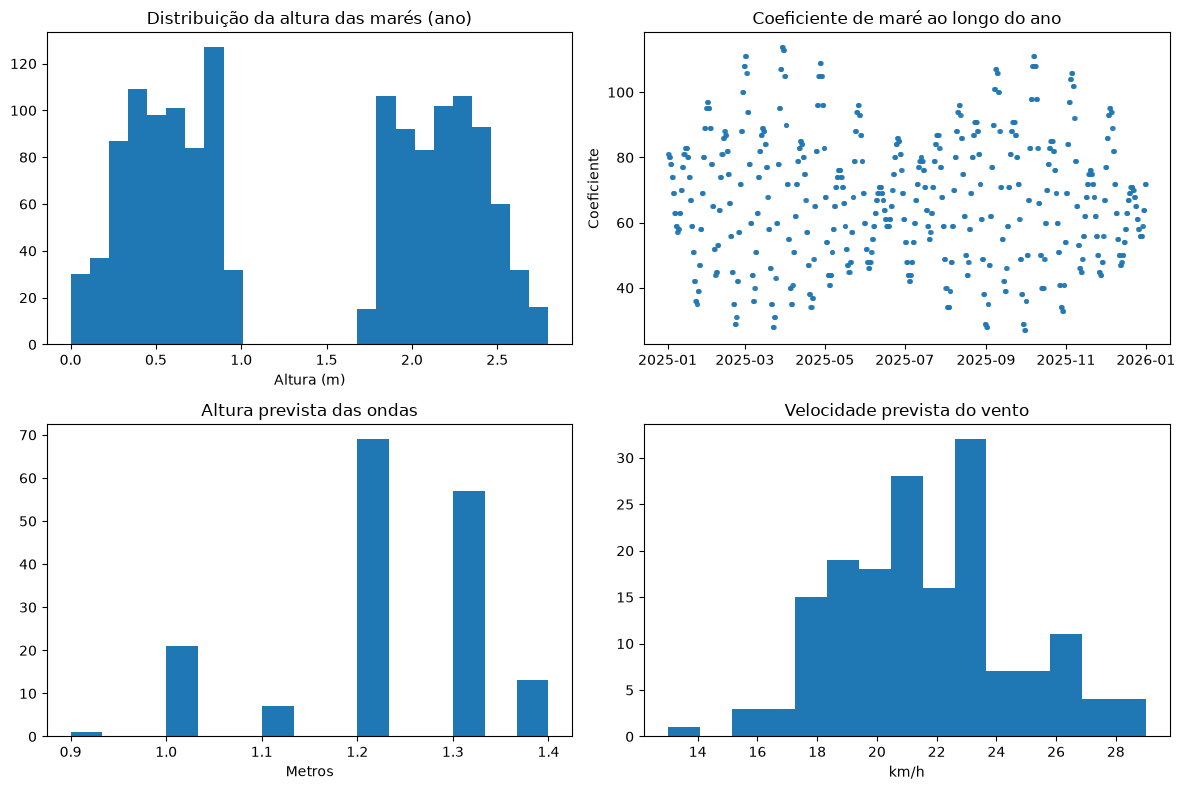

In [20]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
axes[0,0].hist(mares_ano["altura"].dropna(), bins=25)
axes[0,0].set(title="Distribuição da altura das marés (ano)", xlabel="Altura (m)")
if "coeficiente" in mares_ano:
    t = mares_ano.dropna(subset=["coeficiente"])
    axes[0,1].scatter(t["data_hora"], t["coeficiente"], s=7, alpha=.5)
    axes[0,1].set(title="Coeficiente de maré ao longo do ano", ylabel="Coeficiente")
axes[1,0].hist(ondas["valor"].dropna(), bins=15)
axes[1,0].set(title="Altura prevista das ondas", xlabel="Metros")
axes[1,1].hist(vento["valor"].dropna(), bins=15)
axes[1,1].set(title="Velocidade prevista do vento", xlabel="km/h")
plt.tight_layout(); plt.show()

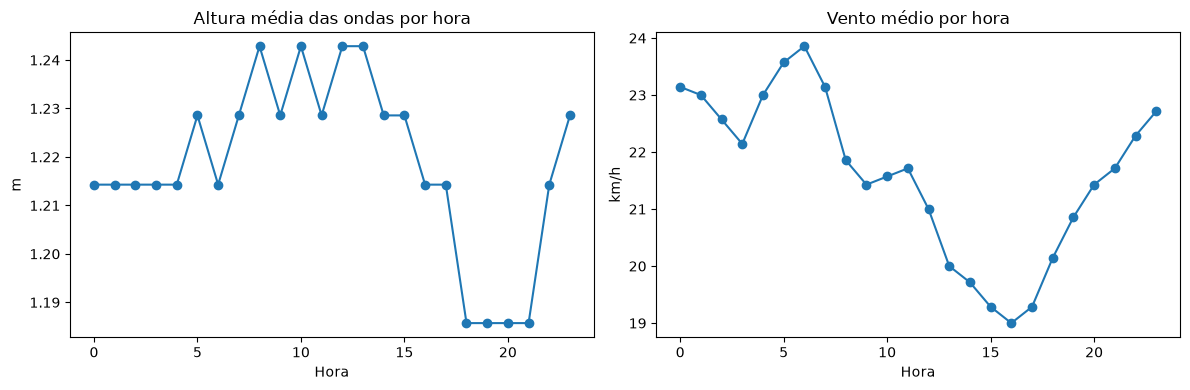

Direções predominantes do vento:
direcao
ESE    56
E      53
ENE    50
SE      9
Name: count, dtype: int64
Não há fase lunar explícita nos CSVs: relação coeficiente/lua não pode ser testada.


In [21]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
ondas.groupby(ondas["data_hora"].dt.hour)["valor"].mean().plot(ax=axes[0], marker="o")
axes[0].set(title="Altura média das ondas por hora", xlabel="Hora", ylabel="m")
vento.groupby(vento["data_hora"].dt.hour)["valor"].mean().plot(ax=axes[1], marker="o")
axes[1].set(title="Vento médio por hora", xlabel="Hora", ylabel="km/h")
plt.tight_layout(); plt.show()
print("Direções predominantes do vento:")
print(vento["direcao"].value_counts().head(8) if "direcao" in vento else "Direção indisponível")
print("Não há fase lunar explícita nos CSVs: relação coeficiente/lua não pode ser testada.")

## 4. Juntar as tabelas — escolhas metodológicas

Ondas e vento são horários; uso **junção interna** pelas horas em comum. Eventos de maré ocorrem cerca de 4 vezes por dia: estimo a altura em cada hora por **interpolação linear no tempo entre dois eventos reais** da tábua mensal (`mares_previsao`). Horas fora do intervalo de eventos conhecido ficam sem estimativa e são descartadas. A curva real da maré não é perfeitamente linear, portanto o resultado é **aproximado**. O histórico anual serve à EDA, não ao encaixe de uma previsão de 7 dias. Não utilizo informações de datas futuras como variáveis de treinamento que não estariam disponíveis no momento da previsão.

In [22]:
onda_h = ondas[["data_hora", "valor"] + (["direcao"] if "direcao" in ondas else [])].rename(
    columns={"valor":"altura_onda", "direcao":"direcao_onda"})
vento_h = vento[["data_hora", "valor"] + (["direcao"] if "direcao" in vento else [])].rename(
    columns={"valor":"velocidade_vento", "direcao":"direcao_vento"})
dataset = onda_h.merge(vento_h, on="data_hora", how="inner", validate="one_to_one")
mares_ref = mares_prev[["data_hora", "altura"]].drop_duplicates("data_hora").sort_values("data_hora")

serie_mare = mares_ref.set_index("data_hora")["altura"]
serie_mare = serie_mare.reindex(serie_mare.index.union(pd.DatetimeIndex(dataset["data_hora"])))
serie_mare = serie_mare.sort_index().interpolate(method="time", limit_area="inside")
dataset["altura_mare"] = serie_mare.reindex(dataset["data_hora"]).to_numpy()
dataset = dataset.dropna(subset=["altura_mare"]).sort_values("data_hora").reset_index(drop=True)
print("Horas comuns com maré interpolável:", len(dataset))
if len(dataset) < 10:
    raise ValueError("Dataset muito pequeno. Confira datas e anos dos três CSVs.")

Horas comuns com maré interpolável: 168


In [23]:
dataset["hora"] = dataset["data_hora"].dt.hour
dataset["dia_semana"] = dataset["data_hora"].dt.dayofweek
dataset["data"] = dataset["data_hora"].dt.strftime("%Y-%m-%d")
dataset["periodo"] = pd.cut(dataset["hora"], bins=[-1, 5, 11, 17, 23],
                            labels=["madrugada", "manha", "tarde", "noite"])
print(dataset.isna().sum().to_string())
display(dataset.head())

data_hora           0
altura_onda         0
direcao_onda        0
velocidade_vento    0
direcao_vento       0
altura_mare         0
hora                0
dia_semana          0
data                0
periodo             0


,data_hora,altura_onda,direcao_onda,velocidade_vento,direcao_vento,altura_mare,hora,dia_semana,data,periodo
0,2026-10-11 00:00:00,1.0,ESE,21.0,SE,0.942725,0,6,2026-10-11,madrugada
1,2026-10-11 01:00:00,1.0,ESE,22.0,SE,1.275289,1,6,2026-10-11,madrugada
2,2026-10-11 02:00:00,1.0,ESE,20.0,SE,1.607852,2,6,2026-10-11,madrugada
3,2026-10-11 03:00:00,1.0,ESE,17.0,ESE,1.940416,3,6,2026-10-11,madrugada
4,2026-10-11 04:00:00,1.0,ESE,21.0,ESE,2.272979,4,6,2026-10-11,madrugada


In [24]:
print("Horas da onda:", len(onda_h), "| Horas do vento:", len(vento_h))
print("Horas em comum:", len(onda_h.merge(vento_h, on="data_hora")))
print("Janela final:", dataset["data_hora"].min(), "a", dataset["data_hora"].max())

Horas da onda: 168 | Horas do vento: 168
Horas em comum: 168
Janela final: 2026-10-11 00:00:00 a 2026-10-17 23:00:00


## 5. Visualizações voltadas à pergunta

Agora com a tabela junta: quando as condições coincidem?

- As horas de onda maior são as mesmas de vento mais fraco, ou elas se
  desencontram?
- Existe relação visível entre altura da maré e altura da onda?
- Quais dias e horas da janela se destacam?

Prefira poucos gráficos legíveis a muitos gráficos.

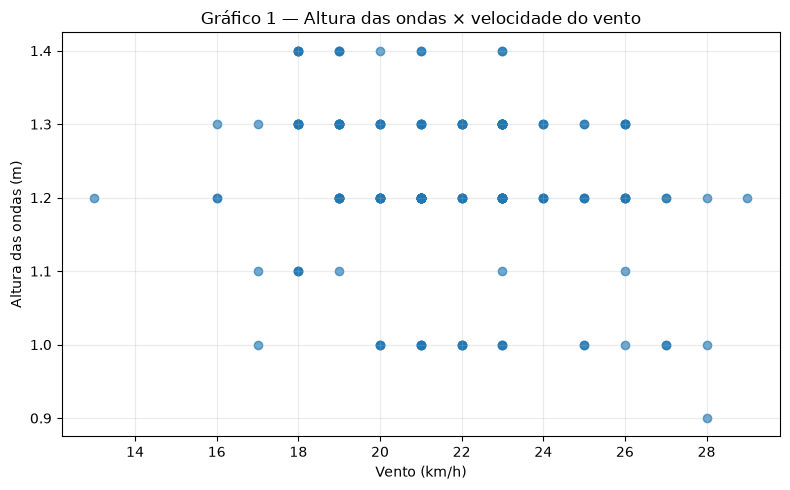

In [25]:
# Gráfico 1: relação entre vento e altura das ondas
plt.figure(figsize=(8, 5))
plt.scatter(dataset["velocidade_vento"], dataset["altura_onda"], alpha=0.65)
plt.title("Gráfico 1 — Altura das ondas × velocidade do vento")
plt.xlabel("Vento (km/h)")
plt.ylabel("Altura das ondas (m)")
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()


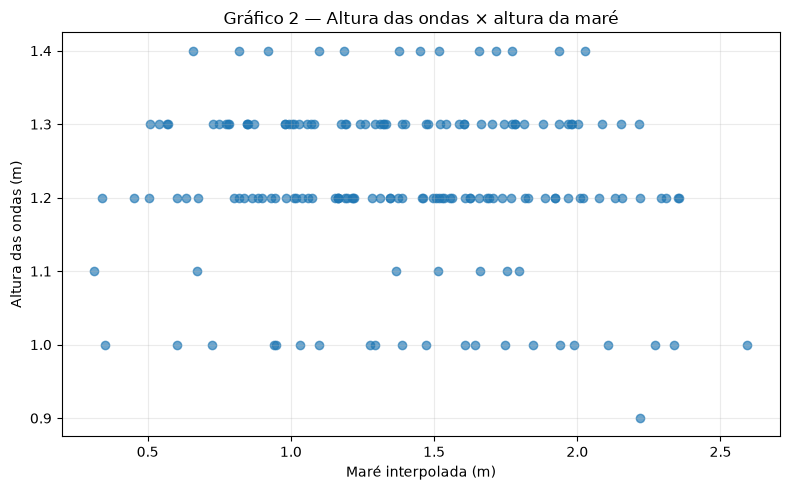

Correlação onda/vento: -0.227
Correlação onda/maré: -0.104


In [26]:
# Gráfico 2: relação entre maré interpolada e altura das ondas
plt.figure(figsize=(8, 5))
plt.scatter(dataset["altura_mare"], dataset["altura_onda"], alpha=0.65)
plt.title("Gráfico 2 — Altura das ondas × altura da maré")
plt.xlabel("Maré interpolada (m)")
plt.ylabel("Altura das ondas (m)")
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()
print("Correlação onda/vento:", round(dataset["altura_onda"].corr(dataset["velocidade_vento"]), 3))
print("Correlação onda/maré:", round(dataset["altura_onda"].corr(dataset["altura_mare"]), 3))


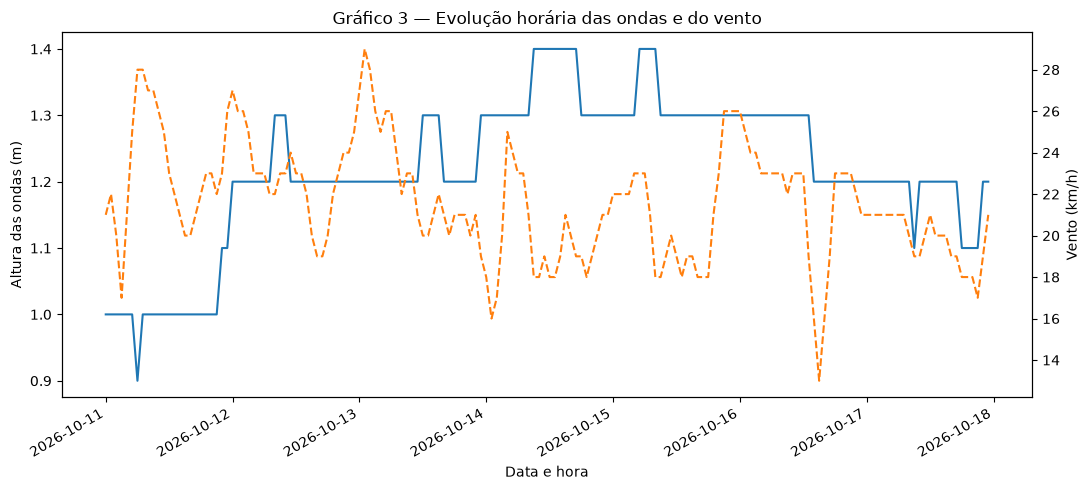

,onda_media,vento_medio,mare_media,horas
data,,,,
2026-10-11,1.00,23.04,1.43,24
2026-10-12,1.21,22.96,1.41,24
2026-10-13,1.22,22.79,1.40,24
2026-10-14,1.34,19.79,1.40,24
2026-10-15,1.32,21.00,1.37,24
2026-10-16,1.26,21.79,1.36,24
2026-10-17,1.18,19.83,1.33,24


Menor vento médio por hora:


hora
16    19.00
15    19.29
17    19.29
14    19.71
13    20.00
Name: velocidade_vento, dtype: float64

In [27]:
# Gráfico 3: evolução temporal das ondas e do vento
fig, ax1 = plt.subplots(figsize=(11, 5))
ax1.plot(dataset["data_hora"], dataset["altura_onda"], label="Ondas (m)")
ax1.set_xlabel("Data e hora")
ax1.set_ylabel("Altura das ondas (m)")
ax2 = ax1.twinx()
ax2.plot(dataset["data_hora"], dataset["velocidade_vento"], linestyle="--", color="tab:orange", label="Vento (km/h)")
ax2.set_ylabel("Vento (km/h)")
plt.title("Gráfico 3 — Evolução horária das ondas e do vento")
fig.autofmt_xdate()
fig.tight_layout()
plt.show()
resumo = dataset.groupby("data").agg(onda_media=("altura_onda", "mean"), vento_medio=("velocidade_vento", "mean"), mare_media=("altura_mare", "mean"), horas=("hora", "size"))
display(resumo.round(2))
print("Menor vento médio por hora:")
display(dataset.groupby("hora")["velocidade_vento"].mean().nsmallest(5).round(2))


## 6. Salvar o dataset processado

Grave o resultado em `../data/processed/dataset.csv`. A Etapa 3 lê esse
arquivo — se as colunas mudarem depois, o notebook de ML muda também.

In [28]:
saida = DIR_PROC / "dataset.csv"
dataset.to_csv(saida, index=False)
print(f"Salvo: {saida} | {len(dataset)} linhas | {len(dataset.columns)} colunas")

Salvo: C:\Users\Eduardo\miniprojeto2\data\processed\dataset.csv | 168 linhas | 10 colunas


## 7. Conclusões

A análise exploratória reuniu 168 observações horárias, correspondentes a sete dias de condições marítimas em João Pessoa. O conjunto de dados apresentou boa integridade, sem valores ausentes nas variáveis analisadas.

A integração das informações de marés, ondas e vento permitiu observar as condições marítimas de maneira conjunta, considerando não apenas a altura das ondas, mas também a intensidade e a direção do vento e a variação do nível do mar.